# Freight Rate Prediction

## 0. Environment and reproducibility


In [1]:
import os
from pathlib import Path

DATA_DIR = Path("/content")
print("Files:", os.listdir(DATA_DIR))

Files: ['.config', 'validation.csv', 'validation-predictions-template.csv', 'december-chart-inputs.csv', 'train-test.csv', 'sample_data']


In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)

# If running locally, put the CSV files in ./data.
# In Google Colab, upload the files when prompted.
DATA_DIR = Path("/content")
DATA_DIR.mkdir(exist_ok=True)

required_files = [
    "train-test.csv",
    "validation.csv",
    "validation-predictions-template.csv",
    "december-chart-inputs.csv",
]

missing_files = [name for name in required_files if not (DATA_DIR / name).exists()]

if missing_files:
    try:
        from google.colab import files
        print("Upload these assessment CSV files:", ", ".join(missing_files))
        uploaded = files.upload()
        for filename, content in uploaded.items():
            if filename in required_files:
                (DATA_DIR / filename).write_bytes(content)
    except ImportError:
        print("Google Colab upload is unavailable. Place the CSV files inside ./data/.")

missing_files = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing files in ./data/: " + ", ".join(missing_files)
        + ". Upload them in Colab or place them in the data folder."
    )

train = pd.read_csv(DATA_DIR / "train-test.csv")
validation = pd.read_csv(DATA_DIR / "validation.csv")
template = pd.read_csv(DATA_DIR / "validation-predictions-template.csv")
december_inputs = pd.read_csv(DATA_DIR / "december-chart-inputs.csv")

# Preserve raw frames; parsed copies are used for analysis.
train_raw = train.copy(deep=True)
validation_raw = validation.copy(deep=True)

for frame in (train, validation):
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")

print("Loaded successfully.")
print("Training:", train.shape)
print("Validation:", validation.shape)
print("Prediction template:", template.shape)
print("December inputs:", december_inputs.shape)

Loaded successfully.
Training: (48000, 14)
Validation: (12000, 13)
Prediction template: (12000, 2)
December inputs: (31, 7)


## 1. Schema and assessment contract checks


In [3]:
EXPECTED_TRAIN_COLUMNS = [
    "load_id", "pickup", "delivery", "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon", "distance", "equipment", "weight",
    "date", "market_index", "quote_signal", "posted_rate"
]
EXPECTED_VALIDATION_COLUMNS = [c for c in EXPECTED_TRAIN_COLUMNS if c != "posted_rate"]

print("Training columns match expected:", list(train_raw.columns) == EXPECTED_TRAIN_COLUMNS)
print("Validation columns match expected:", list(validation_raw.columns) == EXPECTED_VALIDATION_COLUMNS)
print("Template columns:", list(template.columns))
print("December columns:", list(december_inputs.columns))

schema = pd.DataFrame({
    "train_dtype": train_raw.dtypes.astype(str),
    "validation_dtype": validation_raw.dtypes.astype(str)
})
display(schema)

assert "posted_rate" in train.columns, "Target column posted_rate is missing from training data."
assert "posted_rate" not in validation.columns, "Validation file unexpectedly contains the target."
assert len(validation) == 12_000, "Assessment specifies 12,000 validation loads."
assert list(template.columns) == ["load_id", "predicted_rate"], "Unexpected prediction template schema."
assert len(template) == 12_000, "Prediction template should contain 12,000 rows."


Training columns match expected: True
Validation columns match expected: True
Template columns: ['load_id', 'predicted_rate']
December columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


,train_dtype,validation_dtype
date,object,object
delivery,object,object
delivery_lat,float64,float64
delivery_lon,float64,float64
distance,float64,float64
equipment,object,object
load_id,object,object
market_index,float64,float64
pickup,object,object
pickup_lat,float64,float64


## 2. Dataset overview and identifier integrity

In [4]:
overview = pd.DataFrame([
    {
        "dataset": "train_test",
        "rows": len(train),
        "columns": train.shape[1],
        "date_min": train["date"].min(),
        "date_max": train["date"].max(),
        "duplicate_load_id": int(train["load_id"].duplicated().sum()),
        "duplicate_full_rows": int(train_raw.duplicated().sum()),
    },
    {
        "dataset": "validation",
        "rows": len(validation),
        "columns": validation.shape[1],
        "date_min": validation["date"].min(),
        "date_max": validation["date"].max(),
        "duplicate_load_id": int(validation["load_id"].duplicated().sum()),
        "duplicate_full_rows": int(validation_raw.duplicated().sum()),
    }
])
display(overview)

print("Training ID examples:", train["load_id"].head().tolist())
print("Validation ID examples:", validation["load_id"].head().tolist())
print("Template ID set equals validation ID set:",
      set(template["load_id"].astype(str)) == set(validation["load_id"].astype(str)))


,dataset,rows,columns,date_min,date_max,duplicate_load_id,duplicate_full_rows
0,train_test,48000,14,2025-01-01,2025-10-31,0,0
1,validation,12000,13,2025-11-01,2025-12-31,0,0


Training ID examples: ['TR-000001', 'TR-000002', 'TR-000003', 'TR-000004', 'TR-000005']
Validation ID examples: ['TE-000001', 'TE-000002', 'TE-000003', 'TE-000004', 'TE-000005']
Template ID set equals validation ID set: True


## 3. Missing values and invalid numeric values


In [5]:
def quality_table(df, name):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(3),
        "unique_values": df.nunique(dropna=True),
    })
    out.insert(0, "dataset", name)
    return out.reset_index(names="column")

quality = pd.concat([
    quality_table(train_raw, "train"),
    quality_table(validation_raw, "validation")
], ignore_index=True)
display(quality)

numeric_cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
                "distance", "weight", "market_index", "quote_signal"]
invalid_checks = []
for name, df in [("train", train_raw), ("validation", validation_raw)]:
    for col in numeric_cols:
        vals = pd.to_numeric(df[col], errors="coerce")
        invalid_checks.append({
            "dataset": name,
            "column": col,
            "non_numeric_or_infinite": int((vals.isna() & df[col].notna()).sum()
                                             + np.isinf(vals.dropna()).sum()),
            "negative_count": int((vals < 0).sum()) if col in ["distance", "weight"] else np.nan,
            "zero_count": int((vals == 0).sum()),
            "minimum": vals.min(),
            "maximum": vals.max(),
        })
invalid_checks = pd.DataFrame(invalid_checks)
display(invalid_checks)

print("Negative training weights:", int((pd.to_numeric(train_raw["weight"], errors="coerce") < 0).sum()))
print("Negative validation weights:", int((pd.to_numeric(validation_raw["weight"], errors="coerce") < 0).sum()))
print("NOTE: investigate negative weight values before selecting a treatment.")


,column,dataset,dtype,missing_count,missing_pct,unique_values
0,load_id,train,object,0,0.0000,48000
1,pickup,train,object,0,0.0000,64
2,delivery,train,object,0,0.0000,64
3,pickup_lat,train,float64,0,0.0000,64
4,pickup_lon,train,float64,0,0.0000,63
5,delivery_lat,train,float64,0,0.0000,64
6,delivery_lon,train,float64,0,0.0000,63
7,distance,train,float64,0,0.0000,21204
8,equipment,train,object,0,0.0000,3
9,weight,train,float64,300,0.6250,23678


,dataset,column,non_numeric_or_infinite,negative_count,zero_count,minimum,maximum
0,train,pickup_lat,0,NaN,0,28.3576,44.3030
1,train,pickup_lon,0,NaN,0,-121.6985,-69.5000
2,train,delivery_lat,0,NaN,0,28.3576,44.3030
3,train,delivery_lon,0,NaN,0,-121.6985,-69.5000
4,train,distance,0,0.0000,0,70.0000,"3,439.8000"
5,train,weight,0,292.0000,0,"-47,500.0000","47,500.0000"
6,train,market_index,0,NaN,0,0.6764,1.4678
7,train,quote_signal,0,NaN,0,0.6923,3.6103
8,validation,pickup_lat,0,NaN,0,25.5000,44.3030
9,validation,pickup_lon,0,NaN,0,-121.6985,-69.5000


Negative training weights: 292
Negative validation weights: 145
NOTE: investigate negative weight values before selecting a treatment.


## 4. Numeric feature distributions and outlier review


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
pickup_lat,"48,000.0000",35.6475,4.3153,28.3576,28.3576,28.7567,31.9869,35.2948,39.4110,43.4380,44.3030,44.3030
pickup_lon,"48,000.0000",-90.9290,13.4824,-121.6985,-119.7953,-116.7025,-98.4006,-88.0892,-83.2851,-72.1805,-69.5000,-69.5000
delivery_lat,"48,000.0000",35.6412,4.3172,28.3576,28.3576,28.7567,31.9869,35.2948,39.4110,43.4380,44.3030,44.3030
delivery_lon,"48,000.0000",-90.8573,13.4766,-121.6985,-119.7953,-116.7025,-98.4006,-87.5287,-83.2851,-72.1805,-69.5000,-69.5000
distance,"48,000.0000","1,135.8567",728.5644,70.0000,121.8990,236.1000,550.4000,953.3000,"1,645.5250","2,562.3000","3,029.3040","3,439.8000"
weight,"47,700.0000","31,028.8440","9,391.4406","-47,500.0000","9,801.9600","17,490.9500","25,800.0000","31,436.5000","37,018.0000","44,934.2000","47,500.0000","47,500.0000"
market_index,"47,626.0000",1.0834,0.1681,0.6764,0.7829,0.8363,0.9497,1.0558,1.2196,1.3660,1.4072,1.4678
quote_signal,"48,000.0000",2.0625,0.2914,0.6923,1.3047,1.6061,1.8910,2.0558,2.2217,2.5508,2.8840,3.6103
posted_rate,"48,000.0000","2,373.9807","1,486.4932",57.2200,327.1688,599.7385,"1,251.5550","2,030.7600","3,330.7500","4,953.7665","5,972.8340","25,533.0000"


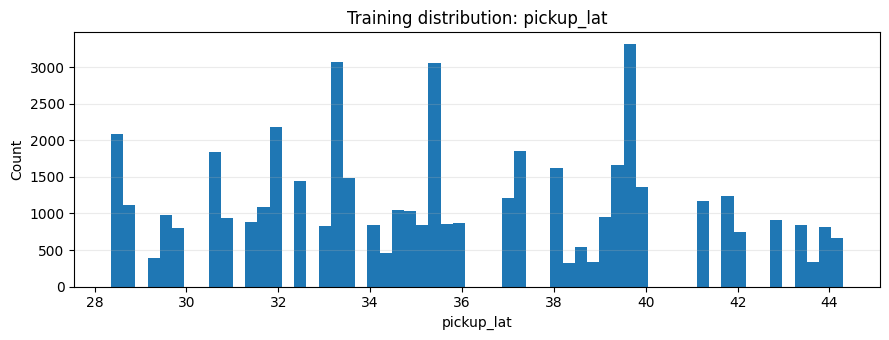

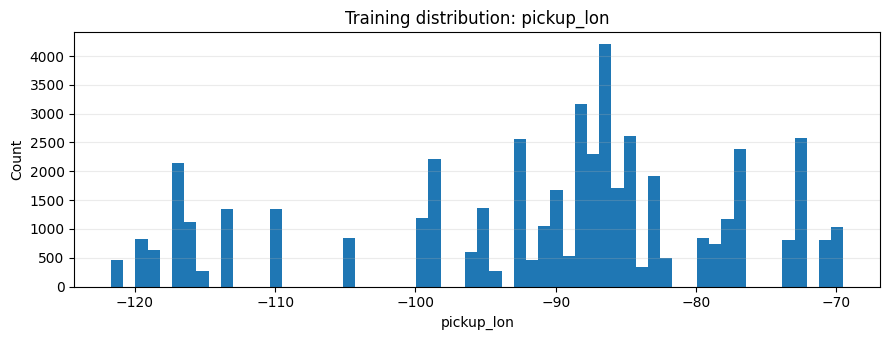

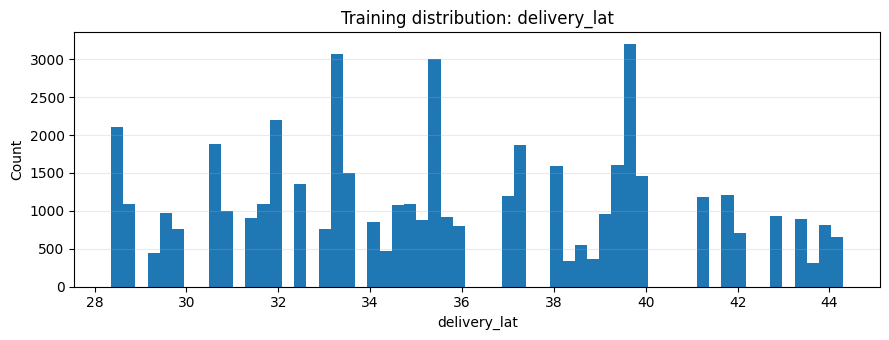

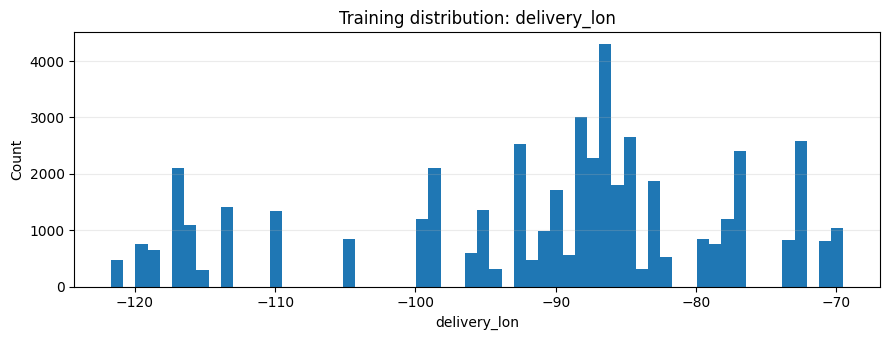

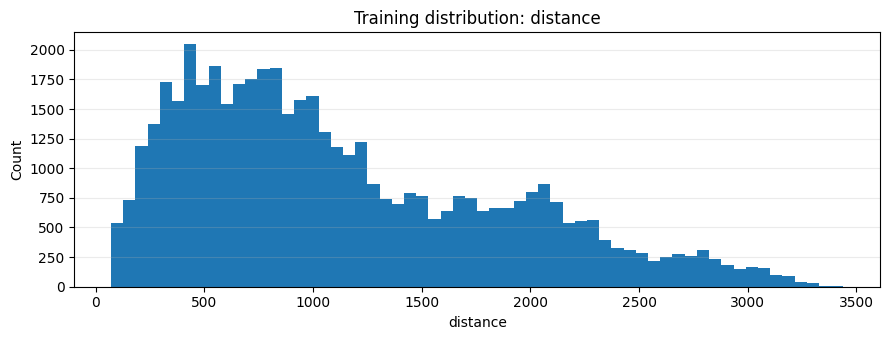

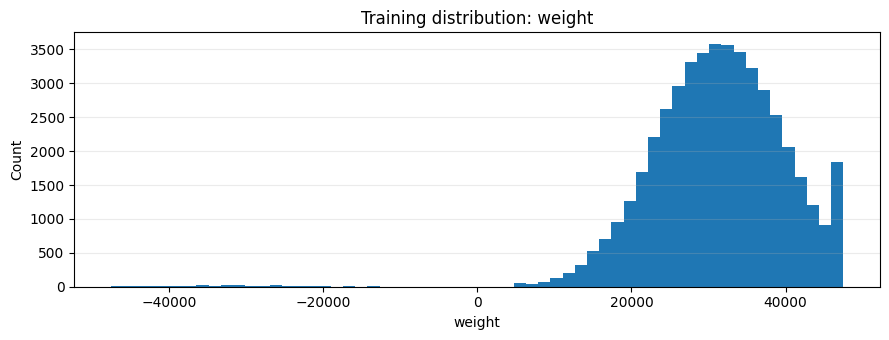

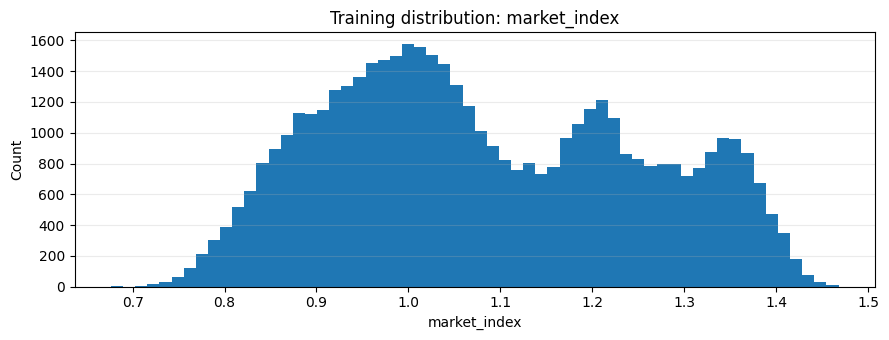

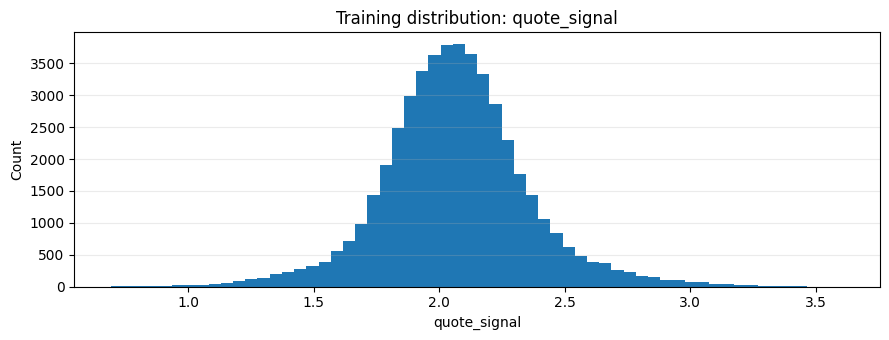

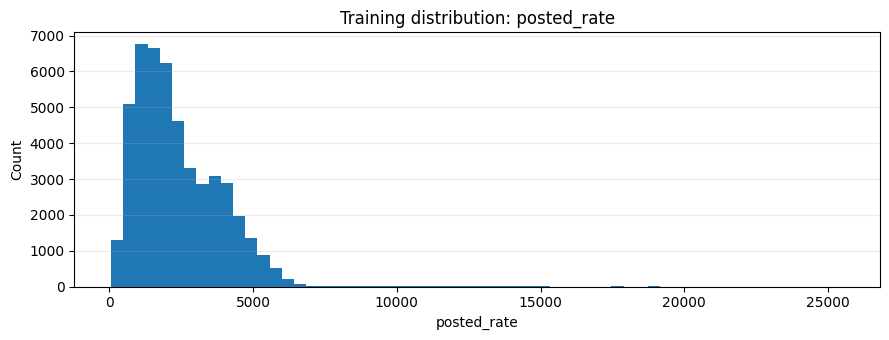

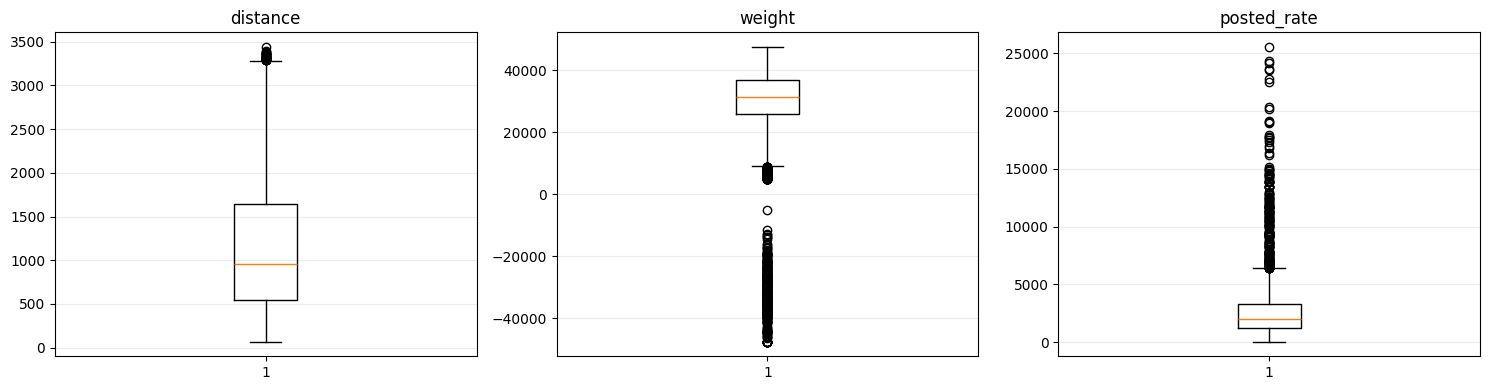

In [6]:
numeric_for_summary = numeric_cols + ["posted_rate"]
display(train[numeric_for_summary].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

for col in numeric_for_summary:
    values = pd.to_numeric(train[col], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.hist(values, bins=60)
    ax.set_title(f"Training distribution: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["distance", "weight", "posted_rate"]):
    ax.boxplot(pd.to_numeric(train[col], errors="coerce").dropna(), vert=True)
    ax.set_title(col)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Target analysis: posted_rate


count   48,000.0000
mean     2,373.9807
std      1,486.4932
min         57.2200
1%         327.1688
5%         599.7385
25%      1,251.5550
50%      2,030.7600
75%      3,330.7500
95%      4,953.7665
99%      5,972.8340
max     25,533.0000
Name: posted_rate, dtype: float64
Non-positive target rows: 0
Missing target rows: 0


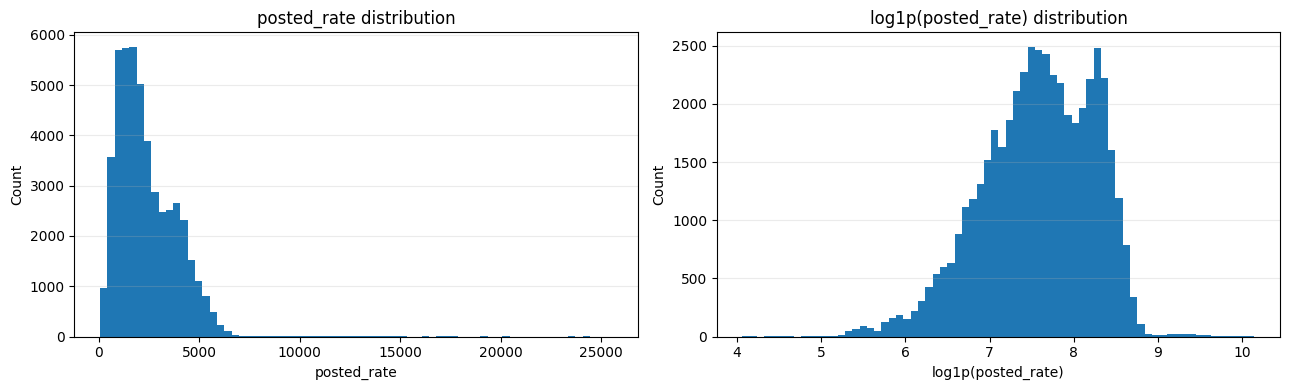

In [7]:
target = pd.to_numeric(train["posted_rate"], errors="coerce")
print(target.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
print("Non-positive target rows:", int((target <= 0).sum()))
print("Missing target rows:", int(target.isna().sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(target.dropna(), bins=70)
axes[0].set_title("posted_rate distribution")
axes[0].set_xlabel("posted_rate")
axes[0].set_ylabel("Count")
axes[0].grid(axis="y", alpha=0.25)

axes[1].hist(np.log1p(target[target > 0].dropna()), bins=70)
axes[1].set_title("log1p(posted_rate) distribution")
axes[1].set_xlabel("log1p(posted_rate)")
axes[1].set_ylabel("Count")
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 6. Numeric relationships and correlation


,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
pickup_lat,1.0000,0.5590,-0.0080,-0.0060,-0.0780,0.0020,-0.0020,-0.0040,-0.0910
pickup_lon,0.5590,1.0000,-0.0090,-0.0120,-0.2730,0.0070,0.0010,0.0140,-0.2550
delivery_lat,-0.0080,-0.0090,1.0000,0.5570,-0.0810,-0.0040,-0.0030,-0.0030,-0.0920
delivery_lon,-0.0060,-0.0120,0.5570,1.0000,-0.2760,-0.0010,-0.0080,0.0110,-0.2570
distance,-0.0780,-0.2730,-0.0810,-0.2760,1.0000,0.0030,-0.0020,-0.0570,0.9090
weight,0.0020,0.0070,-0.0040,-0.0010,0.0030,1.0000,-0.0010,0.0080,0.0350
market_index,-0.0020,0.0010,-0.0030,-0.0080,-0.0020,-0.0010,1.0000,-0.0680,0.0340
quote_signal,-0.0040,0.0140,-0.0030,0.0110,-0.0570,0.0080,-0.0680,1.0000,-0.0400
posted_rate,-0.0910,-0.2550,-0.0920,-0.2570,0.9090,0.0350,0.0340,-0.0400,1.0000


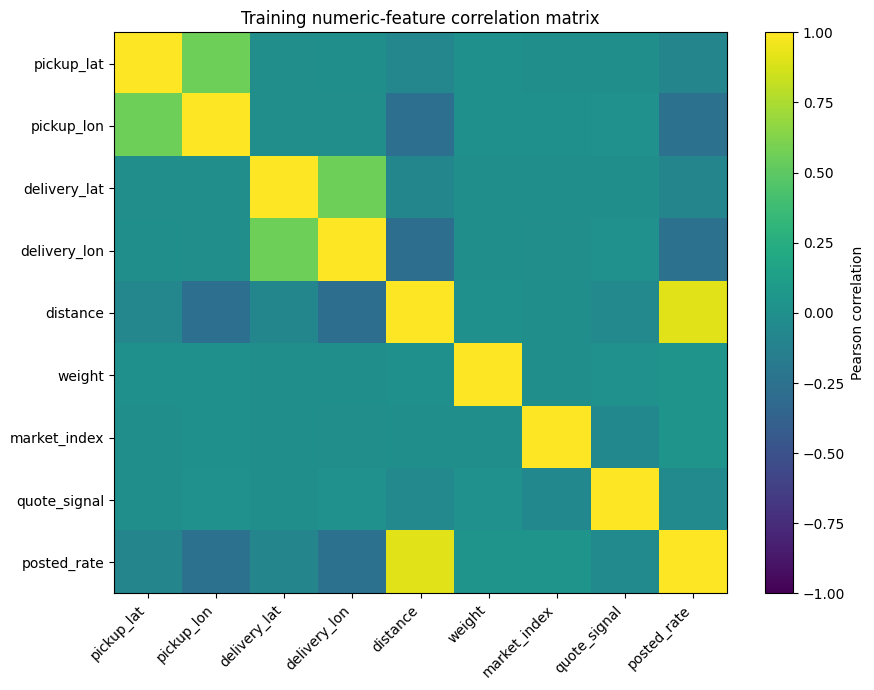

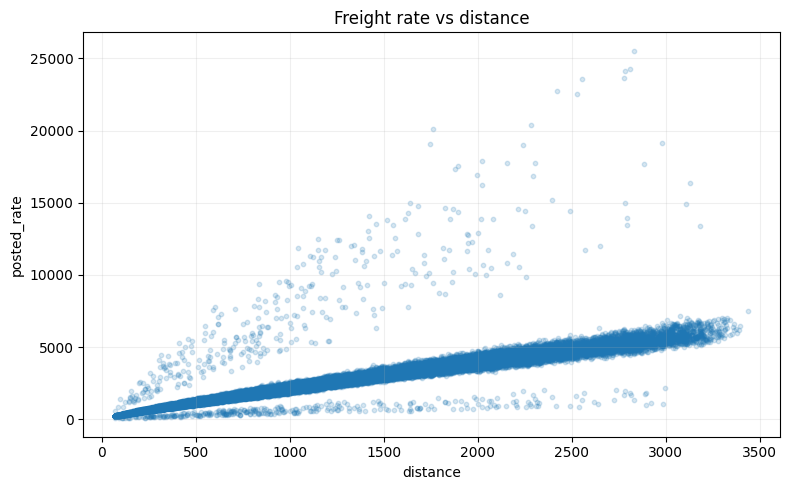

In [8]:
corr_cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
             "distance", "weight", "market_index", "quote_signal", "posted_rate"]
corr = train[corr_cols].corr(numeric_only=True)
display(corr.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Training numeric-feature correlation matrix")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train["distance"], train["posted_rate"], alpha=0.18, s=10)
ax.set_xlabel("distance")
ax.set_ylabel("posted_rate")
ax.set_title("Freight rate vs distance")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 7. Categorical analysis: pickup, delivery and equipment

Top values for equipment


,count
equipment,
Dry Van,27202
Reefer,12045
Flatbed,8753


Top values for pickup


,count
pickup,
Oklahoma City,1242
Lexington,1209
Bakersfield,1193
Fort Wayne,1170
Hartford,1150
Richmond,1140
Nashville,1124
Phoenix,1121
Baton Rouge,1115


Top values for delivery


,count
delivery,
Lexington,1197
Fort Wayne,1176
Baton Rouge,1167
Bakersfield,1156
Hartford,1143
Oklahoma City,1140
Richmond,1109
Atlanta,1096
Phoenix,1090


,count,mean,median,std,min,max
equipment,,,,,,
Dry Van,27202,"2,271.5487","1,953.0350","1,423.0299",57.2200,"25,533.0000"
Reefer,12045,"2,553.6369","2,196.6700","1,589.6708",63.3600,"24,140.2100"
Flatbed,8753,"2,445.0872","2,076.8100","1,505.0531",157.7600,"17,893.1700"


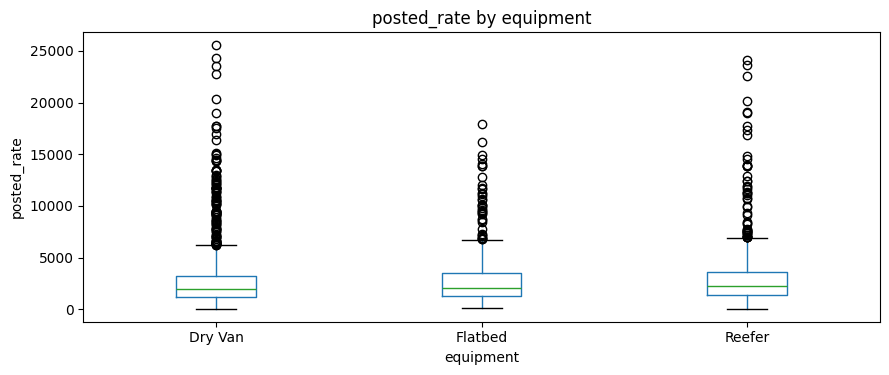

,load_count,median_rate
route,,
Lexington → Atlanta,39,553.6300
Phoenix → Shreveport,39,"3,554.4300"
Columbia → Oklahoma City,39,"2,327.4300"
Fort Wayne → Philadelphia,38,"1,708.8350"
Fort Wayne → Hartford,37,"1,725.9900"
Lexington → Cincinnati,37,377.1000
Shreveport → Hartford,37,"2,812.5200"
Richmond → Phoenix,37,"5,010.8800"
Lexington → Kansas City,37,"1,029.8000"


In [9]:
for col in ["equipment", "pickup", "delivery"]:
    print(f"Top values for {col}")
    display(train[col].value_counts(dropna=False).head(15).rename("count").to_frame())

equipment_summary = (
    train.groupby("equipment", dropna=False)["posted_rate"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("count", ascending=False)
)
display(equipment_summary)

fig, ax = plt.subplots(figsize=(9, 4))
train.boxplot(column="posted_rate", by="equipment", ax=ax, grid=False)
ax.set_title("posted_rate by equipment")
ax.set_xlabel("equipment")
ax.set_ylabel("posted_rate")
plt.suptitle("")
plt.tight_layout()
plt.show()

route_counts = (
    train.assign(route=train["pickup"].astype(str) + " → " + train["delivery"].astype(str))
    .groupby("route")
    .agg(load_count=("load_id", "size"), median_rate=("posted_rate", "median"))
    .sort_values("load_count", ascending=False)
)
display(route_counts.head(20))


## 8. Time trends and temporal coverage

The final validation data is later in time than the development data. Plot monthly target behavior only for the labeled training period; validation has no target.

,month,load_count,mean_rate,median_rate,mean_distance
0,2025-01,4918,"2,255.9670","1,915.2000","1,139.5642"
1,2025-02,4337,"2,273.8048","1,994.2500","1,136.7941"
2,2025-03,5036,"2,372.2681","2,022.9200","1,142.7523"
3,2025-04,4819,"2,372.1623","2,044.2400","1,137.3090"
4,2025-05,4913,"2,421.7763","2,065.5100","1,135.9075"
5,2025-06,4783,"2,497.0301","2,120.2200","1,132.9695"
6,2025-07,4912,"2,415.1620","2,059.1450","1,130.5076"
7,2025-08,4759,"2,338.4077","2,015.7300","1,132.0021"
8,2025-09,4670,"2,406.3740","2,057.1300","1,144.8687"
9,2025-10,4853,"2,379.0514","2,035.9000","1,125.9795"


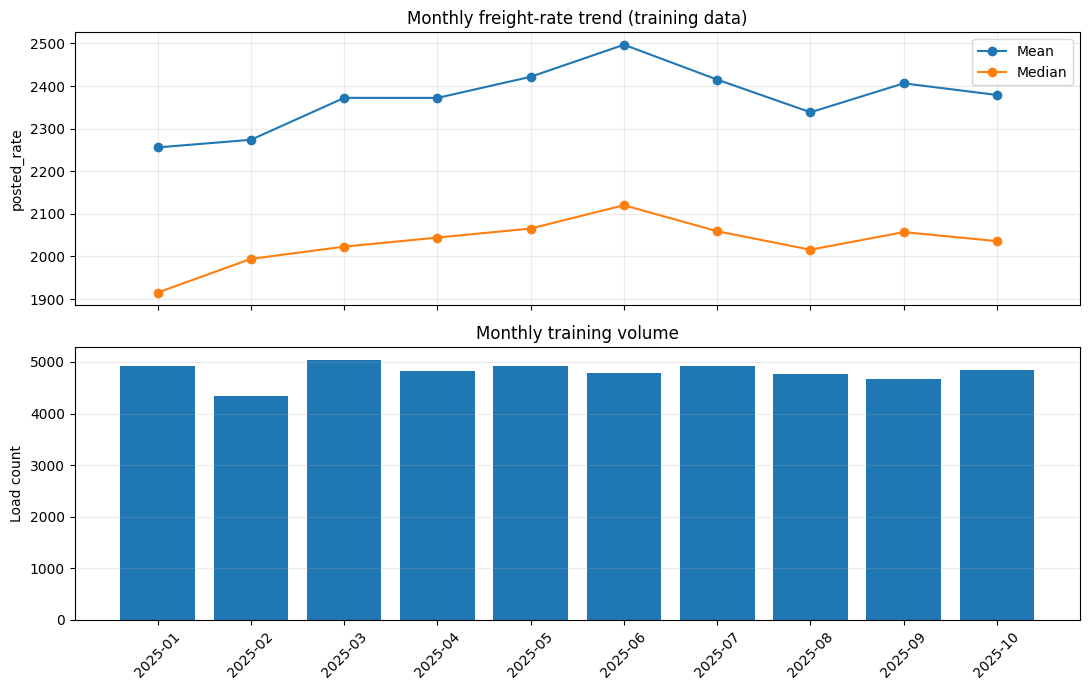

Training months: ['2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10']
Validation months: ['2025-11', '2025-12']


In [10]:
monthly = (
    train.dropna(subset=["date"])
    .assign(month=lambda x: x["date"].dt.to_period("M").astype(str))
    .groupby("month")
    .agg(load_count=("load_id", "size"),
         mean_rate=("posted_rate", "mean"),
         median_rate=("posted_rate", "median"),
         mean_distance=("distance", "mean"))
    .reset_index()
)
display(monthly)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["mean_rate"], marker="o", label="Mean")
axes[0].plot(monthly["month"], monthly["median_rate"], marker="o", label="Median")
axes[0].set_ylabel("posted_rate")
axes[0].set_title("Monthly freight-rate trend (training data)")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].bar(monthly["month"], monthly["load_count"])
axes[1].set_ylabel("Load count")
axes[1].set_title("Monthly training volume")
axes[1].grid(axis="y", alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Training months:", sorted(train["date"].dt.to_period("M").dropna().astype(str).unique()))
print("Validation months:", sorted(validation["date"].dt.to_period("M").dropna().astype(str).unique()))


## 9. Train vs future-validation feature drift

This comparison is descriptive only. Do not use validation labels (there are none) or fit transformations on validation. Large distribution shifts may affect model generalization and should be discussed in the report.

,feature,train_mean,validation_mean,train_median,validation_median,train_missing_pct,validation_missing_pct
0,distance,"1,135.8570","1,141.7730",953.3000,953.6000,0.0000,0.0000
1,weight,"31,028.8440","30,506.6360","31,436.5000","31,193.0000",0.6250,1.3750
2,market_index,1.0830,0.9270,1.0560,0.9230,0.7790,2.0750
3,quote_signal,2.0620,2.0510,2.0560,2.0510,0.0000,0.0000


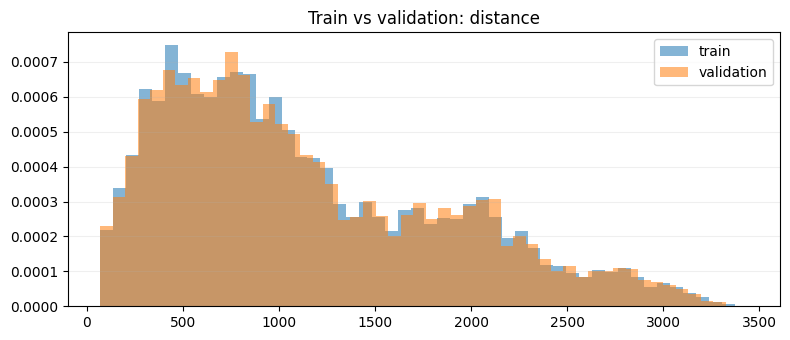

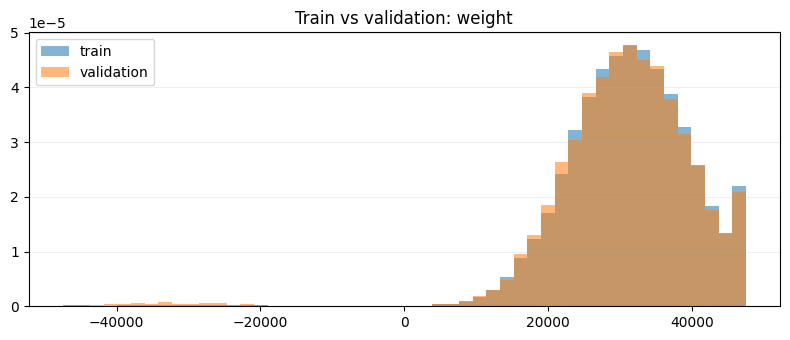

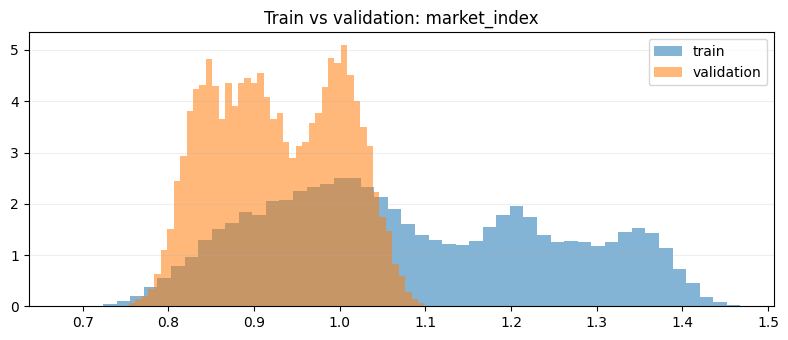

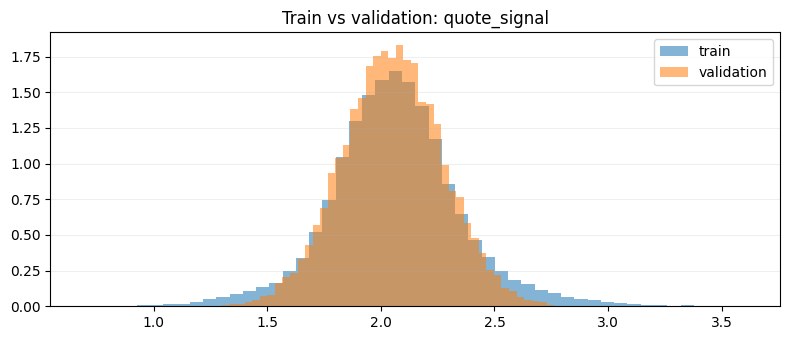

,train_share,validation_share
equipment,,
Dry Van,0.5667,0.5650
Reefer,0.2509,0.2542
Flatbed,0.1824,0.1807


,train_share,validation_share
pickup,,
Lexington,0.0252,0.0251
Fort Wayne,0.0244,0.0242
Phoenix,0.0234,0.0237
Hartford,0.0240,0.0223
Baton Rouge,0.0232,0.0222
Bakersfield,0.0249,0.0220
Mobile,0.0228,0.0220
Richmond,0.0238,0.0217
Nashville,0.0234,0.0213


,train_share,validation_share
delivery,,
Bakersfield,0.0241,0.0249
Oklahoma City,0.0238,0.0242
Lexington,0.0249,0.0235
Hartford,0.0238,0.0232
Richmond,0.0231,0.0225
Fort Wayne,0.0245,0.0223
Columbia,0.0223,0.0222
Phoenix,0.0227,0.0216
Nashville,0.0222,0.0211


In [11]:
comparison_cols = ["distance", "weight", "market_index", "quote_signal"]
comparison_rows = []
for col in comparison_cols:
    tr = pd.to_numeric(train[col], errors="coerce")
    va = pd.to_numeric(validation[col], errors="coerce")
    comparison_rows.append({
        "feature": col,
        "train_mean": tr.mean(),
        "validation_mean": va.mean(),
        "train_median": tr.median(),
        "validation_median": va.median(),
        "train_missing_pct": tr.isna().mean() * 100,
        "validation_missing_pct": va.isna().mean() * 100,
    })
display(pd.DataFrame(comparison_rows).round(3))

for col in comparison_cols:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.hist(pd.to_numeric(train[col], errors="coerce").dropna(), bins=50,
            alpha=0.55, density=True, label="train")
    ax.hist(pd.to_numeric(validation[col], errors="coerce").dropna(), bins=50,
            alpha=0.55, density=True, label="validation")
    ax.set_title(f"Train vs validation: {col}")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

for col in ["equipment", "pickup", "delivery"]:
    tr_share = train[col].value_counts(normalize=True, dropna=False).rename("train_share")
    va_share = validation[col].value_counts(normalize=True, dropna=False).rename("validation_share")
    display(pd.concat([tr_share, va_share], axis=1).fillna(0).sort_values("validation_share", ascending=False).head(20))


## 10. December chart input verification

The README and scorer require one prediction for each day of December 2025 using the supplied fixed shipment scenario. This cell checks the input template; it does not fill predictions.

In [12]:
display(december_inputs.head())
print("December rows:", len(december_inputs))
print("December columns:", list(december_inputs.columns))
print("Date range:", december_inputs["date"].min(), "to", december_inputs["date"].max())
print("Missing values:", december_inputs.isna().sum().to_dict())
print("Unique pickup:", december_inputs["pickup"].unique())
print("Unique delivery:", december_inputs["delivery"].unique())
print("Unique equipment:", december_inputs["equipment"].unique())
print("Unique distance:", december_inputs["distance"].unique())
print("Unique weight:", december_inputs["weight"].unique())


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


December rows: 31
December columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
Date range: 2025-12-01 to 2025-12-31
Missing values: {'pickup': 0, 'delivery': 0, 'distance': 0, 'equipment': 0, 'weight': 0, 'date': 0, 'predicted_rate': 31}
Unique pickup: ['Lexington']
Unique delivery: ['Fort Wayne']
Unique equipment: ['Dry Van']
Unique distance: [360]
Unique weight: [32000]


## 11. Save an EDA summary and charts

The summary file is useful for the assessment report and for recording decisions. It intentionally does not modify the source CSV files.

In [13]:
OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

summary = {
    "train_shape": list(train.shape),
    "validation_shape": list(validation.shape),
    "train_date_min": str(train["date"].min().date()),
    "train_date_max": str(train["date"].max().date()),
    "validation_date_min": str(validation["date"].min().date()),
    "validation_date_max": str(validation["date"].max().date()),
    "train_missing": train_raw.isna().sum().to_dict(),
    "validation_missing": validation_raw.isna().sum().to_dict(),
    "train_duplicate_load_ids": int(train["load_id"].duplicated().sum()),
    "validation_duplicate_load_ids": int(validation["load_id"].duplicated().sum()),
    "train_negative_weights": int((pd.to_numeric(train["weight"], errors="coerce") < 0).sum()),
    "validation_negative_weights": int((pd.to_numeric(validation["weight"], errors="coerce") < 0).sum()),
    "target_summary": train["posted_rate"].describe().to_dict(),
    "target_correlations": train[corr_cols].corr(numeric_only=True)["posted_rate"].drop("posted_rate").to_dict(),
}
with open(OUTPUT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

quality.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index=False)
monthly.to_csv(OUTPUT_DIR / "monthly_training_summary.csv", index=False)

print("Saved:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p)


Saved:
- eda_outputs/data_quality_summary.csv
- eda_outputs/eda_summary.json
- eda_outputs/monthly_training_summary.csv


## 12. EDA conclusions — complete after reviewing your run

Do not invent findings. After running the notebook, fill in this checklist using the actual output:

1. **Target:** Describe `posted_rate` distribution, skew and extreme values.
2. **Strongest signals:** Report numeric relationships with the target, noting correlation is not causation.
3. **Data quality:** Quantify missing values, negative weights, duplicate IDs and any invalid numeric values.
4. **Categoricals:** Note equipment balance and high-frequency pickup/delivery locations.
5. **Time:** Describe month-to-month rate and volume changes in training data.
6. **Drift:** Identify meaningful differences between training and future-validation features.
7. **Decisions to test:** Propose (but do not yet assume) missing-weight treatment, invalid-weight treatment, categorical encoding and date features.

### Modeling protocol for the next phase

Use a chronological evaluation strategy within the labeled January–October development period. For example, train on earlier months and validate on later months with expanding windows, reserving October as a final time-based holdout if sample sizes permit. Fit imputers, encoders and any feature transformations on each training fold only. Compare models using the same folds and report MAE, RMSE and R². After model selection, refit on all labeled development data and generate the two required prediction files.

**Never train on `validation.csv` or infer its target.** It is the final unlabeled prediction set.

In [14]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path("/content")

train_df = pd.read_csv(DATA_DIR / "train-test.csv")
validation_df = pd.read_csv(DATA_DIR / "validation.csv")
december_df = pd.read_csv(DATA_DIR / "december-chart-inputs.csv")
template_df = pd.read_csv(DATA_DIR / "validation-predictions-template.csv")

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("December:", december_df.shape)
print("Template:", template_df.shape)

Training: (48000, 14)
Validation: (12000, 13)
December: (31, 7)
Template: (12000, 2)


In [15]:
# Original datasets ko safe rakhne ke liye copies
train_clean = train_df.copy()
validation_clean = validation_df.copy()
december_clean = december_df.copy()

# Date ko datetime mein convert karein
for df in [train_clean, validation_clean, december_clean]:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Negative weights ko invalid samajh kar missing karein
for df in [train_clean, validation_clean, december_clean]:
    df.loc[df["weight"] < 0, "weight"] = np.nan

# Date se useful features banayein
def add_date_features(df):
    df = df.copy()
    df["month"] = df["date"].dt.month
    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_of_year"] = df["date"].dt.dayofyear
    return df

train_clean = add_date_features(train_clean)
validation_clean = add_date_features(validation_clean)
december_clean = add_date_features(december_clean)

# Common features — teeno datasets mein available
FEATURES = [
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight",
    "month",
    "day_of_week",
    "day_of_year"
]

TARGET = "posted_rate"

# Invalid target rows remove karein
train_clean = train_clean[
    train_clean[TARGET].notna() &
    (train_clean[TARGET] > 0)
].copy()

print("Clean training shape:", train_clean.shape)
print("Features:", FEATURES)
print("Missing values:")
print(train_clean[FEATURES].isnull().sum())

Clean training shape: (48000, 17)
Features: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'month', 'day_of_week', 'day_of_year']
Missing values:
pickup           0
delivery         0
distance         0
equipment        0
weight         592
month            0
day_of_week      0
day_of_year      0
dtype: int64


In [16]:
# October 2025 ko holdout validation banayein
split_date = pd.Timestamp("2025-10-01")

model_train = train_clean[
    train_clean["date"] < split_date
].copy()

model_valid = train_clean[
    train_clean["date"] >= split_date
].copy()

X_train = model_train[FEATURES]
y_train = np.log1p(model_train[TARGET])

X_valid = model_valid[FEATURES]
y_valid = model_valid[TARGET]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Training dates:", model_train["date"].min(), "to", model_train["date"].max())
print("Validation dates:", model_valid["date"].min(), "to", model_valid["date"].max())

Training rows: 43147
Validation rows: 4853
Training dates: 2025-01-01 00:00:00 to 2025-09-30 00:00:00
Validation dates: 2025-10-01 00:00:00 to 2025-10-31 00:00:00


In [17]:
categorical_features = [
    "pickup",
    "delivery",
    "equipment"
]

numeric_features = [
    "distance",
    "weight",
    "month",
    "day_of_week",
    "day_of_year"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.06,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Model train karein
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [18]:
# Validation predictions
valid_log_predictions = model.predict(X_valid)

# Log predictions ko original rate mein convert karein
valid_predictions = np.expm1(valid_log_predictions)

# Positive predictions ensure karein
valid_predictions = np.maximum(valid_predictions, 0.01)

mae = mean_absolute_error(y_valid, valid_predictions)
rmse = np.sqrt(mean_squared_error(y_valid, valid_predictions))
r2 = r2_score(y_valid, valid_predictions)

print("VALIDATION RESULTS")
print("------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2:   {r2:.4f}")

VALIDATION RESULTS
------------------
MAE:  125.94
RMSE: 647.32
R2:   0.8207


In [19]:
X_full = train_clean[FEATURES]
y_full = np.log1p(train_clean[TARGET])

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.06,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

final_model.fit(X_full, y_full)

print("Final model trained on complete training dataset!")

Final model trained on complete training dataset!


In [20]:
X_external = validation_clean[FEATURES]

validation_log_predictions = final_model.predict(X_external)

validation_rates = np.expm1(validation_log_predictions)
validation_rates = np.maximum(validation_rates, 0.01)

# Template ki exact ID order preserve karein
predictions_df = template_df[["load_id"]].copy()

prediction_map = pd.Series(
    validation_rates,
    index=validation_clean["load_id"]
)

predictions_df["predicted_rate"] = predictions_df["load_id"].map(
    prediction_map
)

print(predictions_df.head())
print("Total rows:", len(predictions_df))
print("Missing predictions:", predictions_df["predicted_rate"].isna().sum())

# CSV save karein
predictions_df.to_csv(
    DATA_DIR / "validation_predictions.csv",
    index=False
)

print("Saved: validation_predictions.csv")

     load_id  predicted_rate
0  TE-000001        864.0541
1  TE-000002      5,170.2952
2  TE-000003      5,206.8589
3  TE-000004      4,062.9385
4  TE-000005      1,839.9623
Total rows: 12000
Missing predictions: 0
Saved: validation_predictions.csv


In [21]:
X_december = december_clean[FEATURES]

december_log_predictions = final_model.predict(X_december)

december_rates = np.expm1(december_log_predictions)
december_rates = np.maximum(december_rates, 0.01)

december_output = december_df.copy()
december_output["predicted_rate"] = december_rates

# Required column order
december_output = december_output[
    [
        "pickup",
        "delivery",
        "distance",
        "equipment",
        "weight",
        "date",
        "predicted_rate"
    ]
]

december_output.to_csv(
    DATA_DIR / "december-chart-inputs.csv",
    index=False
)

print(december_output.head())
print("December rows:", len(december_output))
print("Missing predictions:", december_output["predicted_rate"].isna().sum())

print("Saved: december-chart-inputs.csv")

      pickup    delivery  distance equipment  weight        date  predicted_rate
0  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-01        838.3478
1  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-02        842.9403
2  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-03        851.5780
3  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-04        850.9832
4  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-05        846.2592
December rows: 31
Missing predictions: 0
Saved: december-chart-inputs.csv


In [22]:
final_validation = pd.read_csv(
    DATA_DIR / "validation_predictions.csv"
)

final_december = pd.read_csv(
    DATA_DIR / "december-chart-inputs.csv"
)

print("VALIDATION FILE")
print(final_validation.shape)
print(final_validation.head())
print("Missing:", final_validation.isnull().sum().to_dict())

print("\nDECEMBER FILE")
print(final_december.shape)
print(final_december.head())
print("Missing:", final_december.isnull().sum().to_dict())

VALIDATION FILE
(12000, 2)
     load_id  predicted_rate
0  TE-000001        864.0541
1  TE-000002      5,170.2952
2  TE-000003      5,206.8589
3  TE-000004      4,062.9385
4  TE-000005      1,839.9623
Missing: {'load_id': 0, 'predicted_rate': 0}

DECEMBER FILE
(31, 7)
      pickup    delivery  distance equipment  weight        date  predicted_rate
0  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-01        838.3478
1  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-02        842.9403
2  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-03        851.5780
3  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-04        850.9832
4  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-05        846.2592
Missing: {'pickup': 0, 'delivery': 0, 'distance': 0, 'equipment': 0, 'weight': 0, 'date': 0, 'predicted_rate': 0}


In [23]:
# Actual aur predicted rates compare karein
error_df = pd.DataFrame({
    "actual_rate": y_valid.values,
    "predicted_rate": valid_predictions
})

error_df["error"] = (
    error_df["actual_rate"] - error_df["predicted_rate"]
)

error_df["absolute_error"] = error_df["error"].abs()

error_df["percentage_error"] = (
    error_df["absolute_error"] /
    error_df["actual_rate"].clip(lower=0.01)
) * 100

print("ERROR SUMMARY")
print(error_df[[
    "actual_rate",
    "predicted_rate",
    "error",
    "absolute_error",
    "percentage_error"
]].describe().round(2))

print("\nTOP 10 LARGEST ERRORS")
print(
    error_df.nlargest(10, "absolute_error")
    .round(2)
    .to_string(index=False)
)

ERROR SUMMARY
       actual_rate  predicted_rate       error  absolute_error  percentage_error
count   4,853.0000      4,853.0000  4,853.0000      4,853.0000        4,853.0000
mean    2,379.0500      2,388.2400     -9.1800        125.9400            6.3900
std     1,528.7100      1,374.3200    647.3200        635.0200           29.7000
min       104.3800        228.1900 -3,535.0000          0.0000            0.0000
25%     1,231.1300      1,300.7700    -82.8600         23.6700            1.2300
50%     2,035.9000      2,056.7600    -38.1600         50.6600            2.6500
75%     3,305.4500      3,323.4500     -0.1300         92.7400            4.8300
max    19,110.3000      6,587.6800 13,806.7900     13,806.7900          511.5600

TOP 10 LARGEST ERRORS
 actual_rate  predicted_rate       error  absolute_error  percentage_error
 17,514.1100      3,707.3200 13,806.7900     13,806.7900           78.8300
 17,893.1700      4,379.2500 13,513.9200     13,513.9200           75.5300
 19,110.3

In [24]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="median")

baseline.fit(
    X_train,
    y_train
)

baseline_log_predictions = baseline.predict(X_valid)

baseline_predictions = np.expm1(baseline_log_predictions)
baseline_predictions = np.maximum(baseline_predictions, 0.01)

baseline_mae = mean_absolute_error(
    y_valid,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_valid, baseline_predictions)
)

print("MODEL vs BASELINE")
print("-----------------")
print(f"ML Model MAE:       {mae:.2f}")
print(f"Baseline MAE:       {baseline_mae:.2f}")
print(f"ML Model RMSE:      {rmse:.2f}")
print(f"Baseline RMSE:      {baseline_rmse:.2f}")

MODEL vs BASELINE
-----------------
ML Model MAE:       125.94
Baseline MAE:       1146.79
ML Model RMSE:      647.32
Baseline RMSE:      1567.97


In [25]:
import numpy as np
import pandas as pd

pred = pd.read_csv("/content/validation_predictions.csv")

expected_ids = [
    f"TE-{i:06d}" for i in range(1, 12001)
]

assert list(pred.columns) == ["load_id", "predicted_rate"], \
    "Column names ya order ghalat hai"

assert len(pred) == 12000, \
    "Rows ki tadaad 12000 nahi hai"

assert pred["load_id"].tolist() == expected_ids, \
    "Load IDs ya unka order ghalat hai"

assert pred["load_id"].is_unique, \
    "Duplicate load IDs hain"

assert pred["predicted_rate"].notna().all(), \
    "Missing predictions hain"

assert np.isfinite(pred["predicted_rate"]).all(), \
    "Infinite ya invalid predictions hain"

assert (pred["predicted_rate"] > 0).all(), \
    "Zero ya negative predictions hain"

print("SUCCESS: Validation predictions passed all checks!")

SUCCESS: Validation predictions passed all checks!


In [31]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)

Saving requirements.txt to requirements.txt

Uploaded files:
requirements.txt


In [33]:
from pathlib import Path

for filename in ["score.py", "requirements.txt"]:
    path = Path("/content") / filename
    print(filename, "FOUND" if path.exists() else "NOT FOUND")

score.py FOUND
requirements.txt FOUND


In [26]:
dec = pd.read_csv("/content/december-chart-inputs.csv")

expected_columns = [
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight",
    "date",
    "predicted_rate"
]

expected_dates = pd.date_range(
    "2025-12-01",
    "2025-12-31"
)

dec["date"] = pd.to_datetime(dec["date"])

assert list(dec.columns) == expected_columns
assert len(dec) == 31
assert dec["date"].nunique() == 31
assert set(dec["date"]) == set(expected_dates)

assert (dec["pickup"] == "Lexington").all()
assert (dec["delivery"] == "Fort Wayne").all()
assert (dec["distance"] == 360).all()
assert (dec["equipment"] == "Dry Van").all()
assert (dec["weight"] == 32000).all()

assert dec["predicted_rate"].notna().all()
assert np.isfinite(dec["predicted_rate"]).all()
assert (dec["predicted_rate"] > 0).all()

print("SUCCESS: December predictions passed all checks!")
print(dec.head())

SUCCESS: December predictions passed all checks!
      pickup    delivery  distance equipment  weight       date  predicted_rate
0  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-01        838.3478
1  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-02        842.9403
2  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-03        851.5780
3  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-04        850.9832
4  Lexington  Fort Wayne       360   Dry Van   32000 2025-12-05        846.2592


In [32]:
from pathlib import Path

for filename in [
    "score.py",
    "requirements.txt",
    "validation_predictions.csv",
    "december-chart-inputs.csv"
]:
    path = Path("/content") / filename
    print(filename, "FOUND" if path.exists() else "NOT FOUND")

score.py FOUND
requirements.txt FOUND
validation_predictions.csv FOUND
december-chart-inputs.csv FOUND


In [34]:
%cd /content

!python -m pip install -r requirements.txt

!python score.py \
    --predictions /content/validation_predictions.csv \
    --december-predictions /content/december-chart-inputs.csv

/content
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


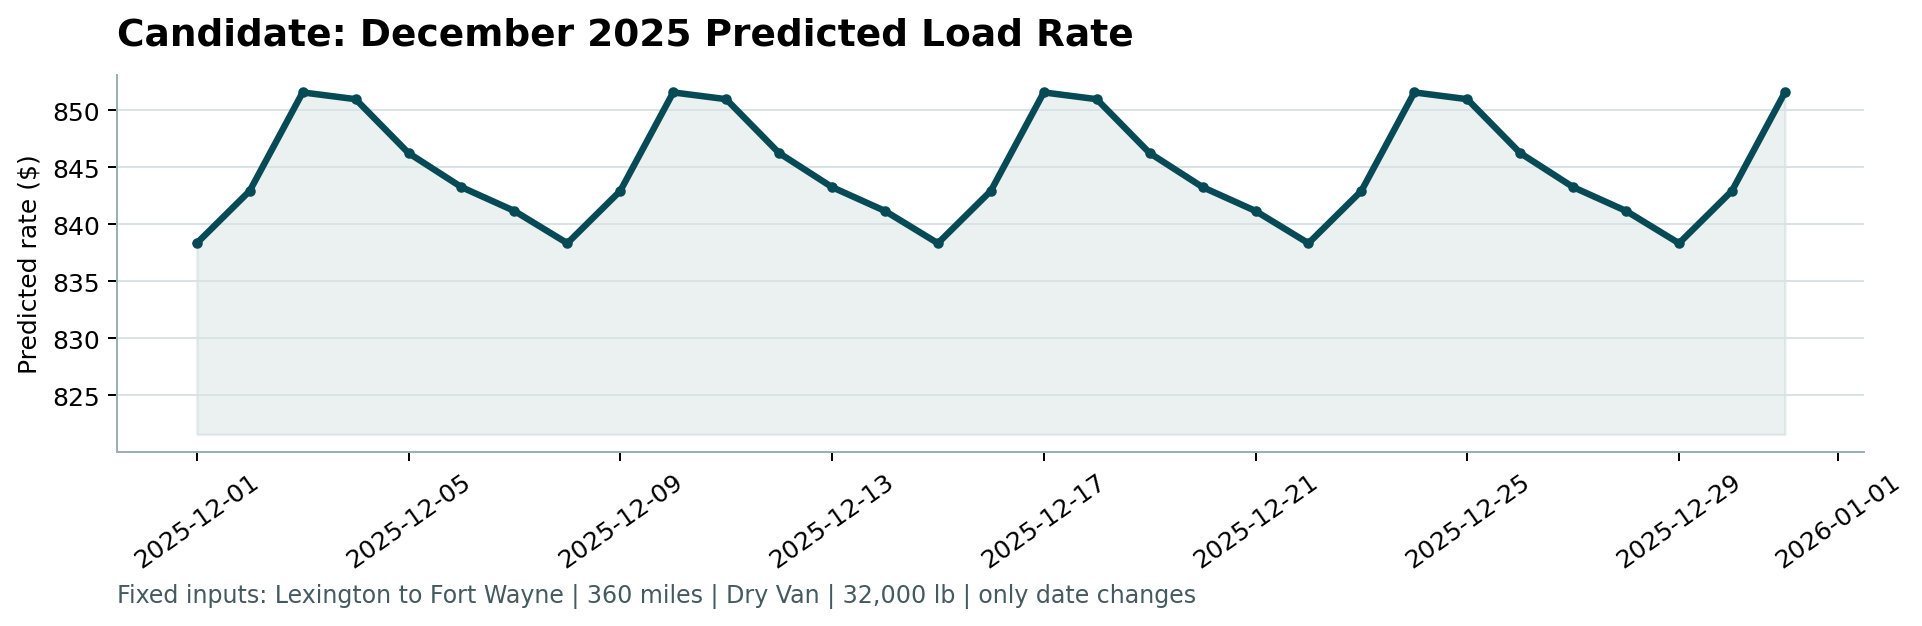

December chart successfully generated!


In [35]:
from pathlib import Path
from IPython.display import display, Image

chart_path = Path("/content/scorer_results/candidate_december.png")

if chart_path.exists():
    display(Image(filename=str(chart_path)))
    print("December chart successfully generated!")
else:
    print("Chart not found. Scorer output/error check karein.")

In [36]:
!pip -q install reportlab

In [37]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)
from reportlab.lib.units import inch
from pathlib import Path

output_pdf = "/content/Spotter_ML_Assessment_Report.pdf"
chart_path = "/content/scorer_results/candidate_december.png"

doc = SimpleDocTemplate(
    output_pdf,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    alignment=TA_CENTER,
    fontSize=19,
    leading=24,
    spaceAfter=18
))

story = []

story.append(Paragraph(
    "Machine Learning Engineer Assessment",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "Freight Rate Prediction — Spotter",
    styles["Heading2"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("1. Project Overview", styles["Heading2"]))
story.append(Paragraph(
    "The objective was to develop a machine learning model to predict "
    "freight load rates using the labeled development dataset. The trained "
    "model was used to generate predictions for 12,000 validation loads "
    "and 31 fixed December 2025 dates.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("2. Data Preparation", styles["Heading2"]))
story.append(Paragraph(
    "The development dataset contained 48,000 rows. The external validation "
    "dataset contained 12,000 rows. The December input contained 31 rows.",
    styles["BodyText"]
))
story.append(Spacer(1, 6))
story.append(Paragraph(
    "The model used pickup, delivery, distance, equipment, weight, month, "
    "day of week and day of year. Date features were extracted from the "
    "load date. Negative weights were treated as missing values, and "
    "missing numeric and categorical values were imputed within the "
    "preprocessing pipeline. Features unavailable in the December input "
    "were not used.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("3. Training and Validation Strategy", styles["Heading2"]))
story.append(Paragraph(
    "A chronological holdout strategy was used. Data from January 1 to "
    "September 30, 2025 (43,147 rows) was used for training. October 2025 "
    "(4,853 rows) was held out for validation. This approach evaluates "
    "performance on a later time period rather than randomly mixing dates.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("4. Model and Validation Results", styles["Heading2"]))
story.append(Paragraph(
    "A preprocessing and HistGradientBoostingRegressor pipeline was trained "
    "on the log-transformed target using log1p. Predictions were converted "
    "back to the original rate scale using expm1.",
    styles["BodyText"]
))
story.append(Spacer(1, 8))

metrics_data = [
    ["Metric", "ML Model", "Median Baseline"],
    ["MAE", f"{mae:.2f}", f"{baseline_mae:.2f}"],
    ["RMSE", f"{rmse:.2f}", f"{baseline_rmse:.2f}"],
    ["R-squared", f"{r2:.4f}", "Not calculated"]
]

metrics_table = Table(metrics_data, colWidths=[2*inch, 1.5*inch, 1.7*inch])
metrics_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#174D5A")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7),
    ("ALIGN", (1, 1), (-1, -1), "CENTER"),
    ("BACKGROUND", (0, 1), (-1, -1), colors.whitesmoke)
]))
story.append(metrics_table)
story.append(Spacer(1, 10))

story.append(Paragraph(
    "The model achieved lower MAE and RMSE than the median baseline on "
    "the October holdout. The large difference between MAE and RMSE indicates "
    "that some individual predictions had substantially larger errors. "
    "The largest observed absolute error was approximately $13,806.79.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("5. Final Prediction Checks", styles["Heading2"]))
story.append(Paragraph(
    "The final validation file contains 12,000 rows with the required "
    "load_id and predicted_rate columns. All predictions were present, "
    "finite and positive. The December file contains 31 dates, from "
    "December 1 through December 31, 2025, with all required fixed inputs "
    "and positive predictions. The provided scorer successfully validated "
    "both files.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("6. December 2025 Prediction Chart", styles["Heading2"]))

if Path(chart_path).exists():
    chart = Image(chart_path, width=7.0*inch, height=2.3*inch)
    story.append(chart)
else:
    story.append(Paragraph(
        "December chart file was not found.",
        styles["BodyText"]
    ))

story.append(Spacer(1, 8))
story.append(Paragraph(
    "Fixed inputs: Lexington to Fort Wayne, 360 miles, Dry Van, "
    "32,000 lb. Only the date changes.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("7. Limitations", styles["Heading2"]))
story.append(Paragraph(
    "The model's validation performance was measured on the October holdout. "
    "The true rates for the 12,000 external validation rows were not available "
    "for local evaluation. Final validation metrics will be calculated by "
    "Spotter after submission. Large-rate loads were among the most difficult "
    "cases for this model.",
    styles["BodyText"]
))

doc.build(story)

print("PDF report created:", output_pdf)

PDF report created: /content/Spotter_ML_Assessment_Report.pdf


In [38]:
from google.colab import files

files.download("/content/Spotter_ML_Assessment_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>